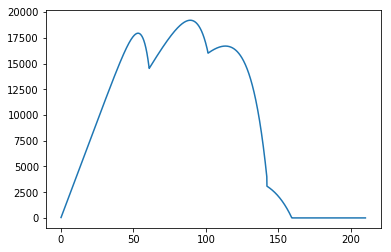

In [3]:
import numpy as np
import random
import matplotlib.pyplot as plt

class Shaded(object):
    def __init__(self):
        self.G = [100, 1000]  # read irradiance # Solar radiation in mW / sq.cm / Esto es la irradiancia para panel cuando [sombredo,sin_sombra]
        #self.T = 25  # read temperature # ojo con kelvin 273
        #self.SH = [4, 10, 7, 10, 10, 10]  # Shaded modules
        self.Mp = 10  # Modules in parallel
        self.Ng = [40, 38, 22]  # Parallel-connected series assemblies
        self.Iscr_sh = 0.375

    def data(self, Irradiancia_maxima, T, V, SH):

        # G_ar = np.array(G) # Solar radiation in mW/sq.cm

        pv = Panel()
        IUN = []
        ISH = []
        Ipv = []

        for j in range(len(self.Ng)):
            # IUN_i = pv.calc_pv(Irradiancia_maxima, T, V, SH[j*2])[0] # asi estaria bien hecho, pero como dejamos fija la irradiancia maxima lo tomamos del self.G[1]
            IUN_i = pv.calc_pv(self.G[1], T, V, SH[j*2])[0]
            if IUN_i < 0:
                IUN_i = 0
            IUN.append(IUN_i)
            ISH_i = pv.calc_pv(self.G[0], T, V, SH[j*2+1])[0]
            if ISH_i< 0:
                ISH_i = 0
            ISH.append(ISH_i)

        for jj in (range(len(self.Ng))):
            if IUN[jj] > self.Iscr_sh:
                Ipv.append(IUN[jj])
            else:
                Ipv.append(ISH[jj])

        
        IT = Ipv[0] * self.Ng[0] + Ipv[1] * self.Ng[1] + Ipv[2] * self.Ng[2]
        VT = V
        PT = IT*VT
        return IT, VT, PT 

class Panel(object):

    def __init__(self):
        self.TK = 273 # Kelvin temperature
        self.Tr1 = 40  # Reference temperature in degree fahrenheit
        # self.S = 100  # Solar radiation in mW / sq.cm
        self.ki = 0.00023  # in A / K
        self.Iscr = 3.75  # SC Current at ref.temp. in A
        self.Irr = 0.000021  # in A
        self.k = 1.38065e-23  # Boltzmann constant
        self.q = 1.6022e-19  # charge of an electron
        self.A = 2.15 # ideality factor
        self.Eg0 = 1.166 # band gap energy
        self.alpha = 0.473
        self.beta = 636
        # panel composed of Np parallel modules each one including Ns photovoltaic cells connected
        self.Np = 1
        self.Ns = 36
        self.Rs = 1e-5
        self.Rsh = 1e5

    def calc_pv(self, G, T, vx, SH):
        # cell temperature
        Tcell = T + self.TK
        # cell reference temperature in kelvin
        Tr = ((self.Tr1 - 32) * (5 / 9)) + 273
        # band gap energy of semiconductor
        Eg = self.Eg0 - (self.alpha * Tcell * Tcell) / (Tcell + self.beta) * self.q
        # generated photocurrent
        Iph = (self.Iscr + self.ki * (Tcell - Tr)) * (G / 1000)
        # cell reverse saturation current
        Irs = self.Irr * ((Tcell / Tr) ** 3) * np.exp(self.q * Eg / (self.k * self.A) * ((1 / Tr) - (1 / Tcell)))
        # panel output current
        I = self.Np * Iph - self.Np * Irs * (np.exp(self.q / (self.k * Tcell * self.A) * vx * (1/SH) / self.Ns) - 1)
        
        Vt = self.k * Tcell * self.A / self.q 
        diff = float('inf')
        steps = 0
        
        while diff > 1e-3:
            steps += 1
            if steps > 100:
                break
            fv = I - (Iph*self.Np - Irs*self.Np*(np.exp(((vx/(self.Ns*SH)) + ((I*self.Rs)/self.Np))/Vt) - 1) - ((((vx*self.Np)/self.Ns) + (I*self.Rs))/self.Rsh))
#             fv = I - (Iph*self.Np - Irs*self.Np*(np.exp(((vx/(self.Ns*SH)) + ((I*self.Rs)/self.Np))/Vt) - 1))
            fdv = 1 + (self.Rs/self.Rsh) + ((np.exp(((vx/(self.Ns*SH)) + ((I*self.Rs)/self.Np))/Vt)*Irs*self.Rs)/(Vt))
#             fdv = 1                      + ((np.exp(((vx/(self.Ns*SH)) + ((I*self.Rs)/self.Np))/Vt)*Irs*self.Rs)/(Vt))
            # In = I - (fv./fdv)
            In = I - fv/fdv
            diff = abs(abs(In) - abs(I))
            I = In
        
        # panel output voltage
        V = vx # este es el Vg?
        # panel power
        P = vx * I

        return I,V,P

                
Voltage = 0.
Power = 0.
Temp = 25.
Irr = 1000.
# a = random.sample([1,2,3,4,5,6,7,8,9,10],1)[0]
# b = random.sample([1,2,3,4,5,6,7,8,9,10],1)[0]
# c = random.sample([1,2,3,4,5,6,7,8,9,10],1)[0]
a = 3
b = 7
c = 5
SH = [a, 10, b, 10, c, 10]

powerlst = []
voltagelst = []

for i in range(2100):
    Voltage += 0.1
    pv = Shaded()
    Current, Voltage, Power = pv.data(Irr, Temp, Voltage, SH)
    powerlst.append(Power)
    voltagelst.append(Voltage)

plt.plot(voltagelst, powerlst)

In [4]:
Pmax = np.zeros((11, 11, 11))
for i in range(1, 11):
    for j in range(1, 11):
        for k in range(1, 11):
            Voltage = 0.
            Power = 0.
            Temp = 25.
            Irr = 1000.
            a, b, c = i, j, k
            SH = [a, 10, b, 10, c, 10]
            powerlst = []
            for ite in range(2100):
                Voltage += 0.1
                pv = Shaded()
                Current, Voltage, Power = pv.data(Irr, Temp, Voltage, SH)
                powerlst.append(Power)
            Pmax[i][j][k] = round(max(powerlst), 2)
            print(i, j, k, Pmax[i][j][k])

1 1 1 5384.78
1 1 2 5546.95
1 1 3 5549.17
1 1 4 6641.48
1 1 5 8271.94
1 1 6 9845.54
1 1 7 11284.27
1 1 8 12454.19
1 1 9 13238.65
1 1 10 13670.59
1 2 1 5697.4
1 2 2 6946.66
1 2 3 7308.25
1 2 4 7329.6
1 2 5 8271.94
1 2 6 9845.54
1 2 7 11284.27
1 2 8 12454.19
1 2 9 13238.65
1 2 10 13670.59
1 3 1 7269.28
1 3 2 7734.43
1 3 3 10418.5
1 3 4 10917.38
1 3 5 10978.71
1 3 6 10992.49
1 3 7 11284.27
1 3 8 12454.19
1 3 9 13238.65
1 3 10 13670.59
1 4 1 9684.71
1 4 2 9684.71
1 4 3 11486.59
1 4 4 13886.61
1 4 5 14492.37
1 4 6 14607.94
1 4 7 14639.18
1 4 8 14650.59
1 4 9 14655.7
1 4 10 14658.38
1 5 1 12084.13
1 5 2 12084.13
1 5 3 12084.13
1 5 4 15157.63
1 5 5 17344.91
1 5 6 18031.93
1 5 7 18207.7
1 5 8 18263.28
1 5 9 18285.25
1 5 10 18295.53
1 6 1 14442.25
1 6 2 14442.25
1 6 3 14442.25
1 6 4 15457.95
1 6 5 18758.56
1 6 6 20777.91
1 6 7 21522.55
1 6 8 21757.32
1 6 9 21841.85
1 6 10 21877.83
1 7 1 16698.8
1 7 2 16698.8
1 7 3 16698.8
1 7 4 16698.8
1 7 5 19207.56
1 7 6 22282.18
1 7 7 24147.41
1 7 8 24921.0


6 5 9 29394.48
6 5 10 29406.83
6 6 1 25965.76
6 6 2 25965.76
6 6 3 25965.76
6 6 4 25965.76
6 6 5 30028.66
6 6 6 32308.5
6 6 7 32968.2
6 6 8 33161.36
6 6 9 33230.55
6 6 10 33260.22
6 7 1 27300.72
6 7 2 27300.72
6 7 3 27300.72
6 7 4 27300.72
6 7 5 30574.68
6 7 6 33540.42
6 7 7 34521.33
6 7 8 34811.7
6 7 9 34913.09
6 7 10 34955.46
6 8 1 27759.76
6 8 2 27759.76
6 8 3 27759.76
6 8 4 27759.76
6 8 5 30743.58
6 8 6 33935.06
6 8 7 35035.6
6 8 8 35363.16
6 8 9 35476.82
6 8 10 35523.92
6 9 1 27927.84
6 9 2 27927.84
6 9 3 27927.84
6 9 4 27927.84
6 9 5 30807.72
6 9 6 34078.03
6 9 7 35220.39
6 9 8 35560.97
6 9 9 35678.83
6 9 10 35727.55
6 10 1 27999.19
6 10 2 27999.19
6 10 3 27999.19
6 10 4 27999.19
6 10 5 30836.58
6 10 6 34139.07
6 10 7 35298.03
6 10 8 35643.7
6 10 9 35763.19
6 10 10 35812.55
7 1 1 17375.85
7 1 2 17375.85
7 1 3 17375.85
7 1 4 17375.85
7 1 5 19799.61
7 1 6 22944.61
7 1 7 24824.65
7 1 8 25592.88
7 1 9 25873.78
7 1 10 25986.37
7 2 1 17375.85
7 2 2 17375.85
7 2 3 17375.85
7 2 4 17375.8

In [5]:
print(Pmax)

[[[    0.       0.       0.   ...     0.       0.       0.  ]
  [    0.       0.       0.   ...     0.       0.       0.  ]
  [    0.       0.       0.   ...     0.       0.       0.  ]
  ...
  [    0.       0.       0.   ...     0.       0.       0.  ]
  [    0.       0.       0.   ...     0.       0.       0.  ]
  [    0.       0.       0.   ...     0.       0.       0.  ]]

 [[    0.       0.       0.   ...     0.       0.       0.  ]
  [    0.    5384.78  5546.95 ... 12454.19 13238.65 13670.59]
  [    0.    5697.4   6946.66 ... 12454.19 13238.65 13670.59]
  ...
  [    0.   18728.49 18728.49 ... 27365.44 28122.21 28434.62]
  [    0.   20343.07 20343.07 ... 28834.06 30256.55 30923.84]
  [    0.   21417.4  21417.4  ... 29554.36 31515.71 32571.46]]

 [[    0.       0.       0.   ...     0.       0.       0.  ]
  [    0.    5719.04  7137.71 ... 12454.19 13238.65 13670.59]
  [    0.    8666.45 10769.55 ... 12454.19 13238.65 13670.59]
  ...
  [    0.   18728.49 18728.49 ... 27365.44 28122

In [6]:
np.save('Pmax2.npy', Pmax)
# Pmax = np.load('Pmax.npy')